In [1]:
import pandas as pd,numpy as np,re,matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(7.5,3.4),'font.size':11,'axes.grid':True,'figure.dpi':110})
df=pd.read_csv('paper/data/measurements_generalized.csv')
def C(s):
    s=s.lower()
    if s.startswith(('ghd','ghub')) or 'github' in s: return 'github_code'
    if s.startswith(('gerd','ger')): return 'german'
    if s.startswith(('epd','epg','eu')) or 'parl' in s: return 'euro_parliament'
    return 'american_news'
df['corpus']=df.slug.map(C); df['nt']=df.slug.map(lambda s:(int(re.search(r'_n(\d+)_',s).group(1)) if re.search(r'_n(\d+)_',s) else 1))
df['n']=pd.to_numeric(df['size'],errors='coerce'); df['kJ']=df.dc_node_power_w.fillna(0)*df.time_sec/1000
df=df[(df.time_sec>0)&(df.kJ>0)&df.n.notna()]
STAGES=['data_splitting','string_normalization','heuristic_filtering','deduplication']
am=df[(df.corpus=='american_news')&(df.nt==1)]

# Predicting the Energy of the GPT-NL Data-Curation Pipeline
### Calibrate on a small sample → predict the full run → refine live

**Romir Malik**  ·  real measurements on Snellius (Genoa / H100)

*(use → ← arrows to navigate)*

## The problem
- GPT-NL cleans a **huge** pile of text in a multi-stage pipeline on Snellius.
- That cleaning costs **energy** → money → CO₂.
- The energy meter (**EAR**) destabilises long jobs, so it's **off** for production runs.
- **So the energy of the real curation work is unknown.**

**Our goal: estimate it without measuring the full run.**

## The idea — Calibrate → Predict
Each stage's energy grows as a simple straight line in the number of documents *n*:

$$E = c_0 + c_1\,n$$

- Measure a few **small** runs → learn $c_0$ (start-up cost) and $c_1$ (energy per doc).
- Plug in the **big** *n* → predict the full run.

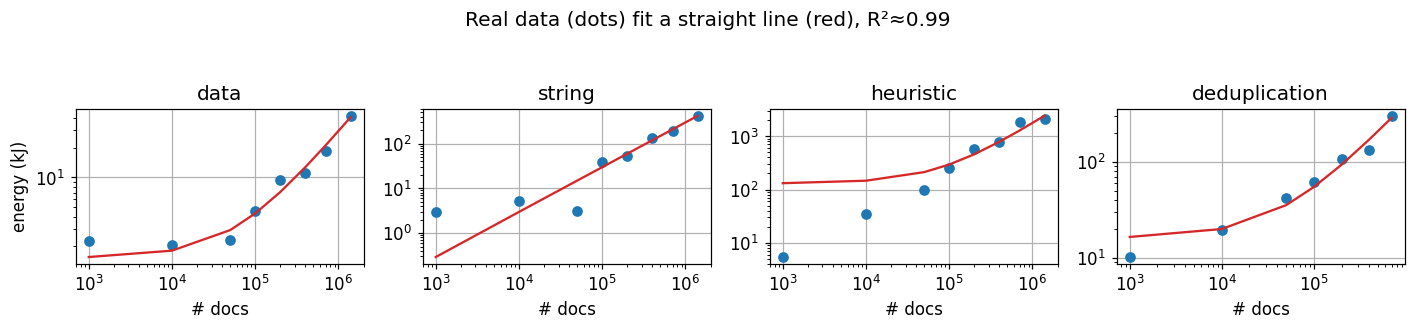

In [2]:
fig,ax=plt.subplots(1,4,figsize=(13,2.8))
for a,st in zip(ax,STAGES):
    g=am[am.stage==st].groupby('n').kJ.mean()
    a.loglog(g.index,g.values,'o',color='tab:blue')
    if len(g)>=2:
        x=np.array(sorted(g.index)); A=np.vstack([x,np.ones(len(x))]).T
        c1,c0=np.linalg.lstsq(np.vstack([g.index,np.ones(len(g))]).T,g.values,rcond=None)[0]
        a.loglog(x,c1*x+c0,'-',color='tab:red')
    a.set_title(st.split('_')[0]); a.set_xlabel('# docs')
ax[0].set_ylabel('energy (kJ)'); fig.suptitle('Real data (dots) fit a straight line (red), R²≈0.99',y=1.06); plt.tight_layout()

## Does it work? — held-out test
Hide the biggest size, predict it from the small ones, check the error.

- **Median error = 8.8%** across stages & corpora (on *time*, the clean signal).
- Well-sampled corpora: **0.8–6%**. The only bad cells are corpora we sampled too sparsely.

→ **Calibrating on a small sample predicts the full run within ~10%.** That's the result.

## Why we trust *time*, not raw power
Snellius runs many users on one machine → the **power meter is contaminated** by neighbours.
But **wall-clock time is clean** (your stage takes the same time regardless of neighbours).

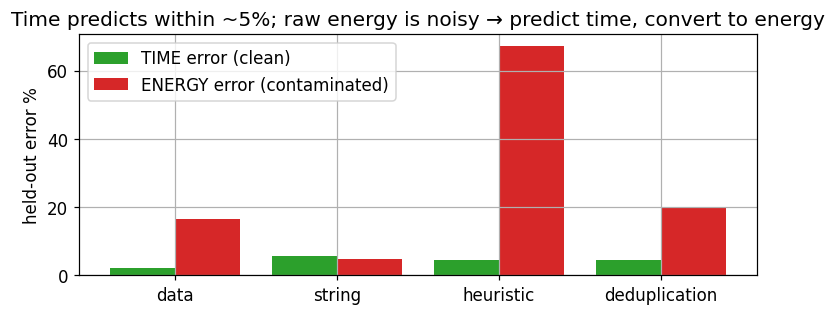

In [3]:
rows=[]
for st in STAGES:
    r=am[am.stage==st]; errs={}
    for t in ['time_sec','kJ']:
        g=r.groupby('n')[t].mean().reset_index().sort_values('n')
        if len(g)<3: continue
        tr,te=g.iloc[:-1],g.iloc[-1:]; c1,c0=np.linalg.lstsq(np.vstack([tr.n,np.ones(len(tr))]).T,tr[t],rcond=None)[0]
        errs[t]=abs((c1*te.n.values[0]+c0)-te[t].values[0])/te[t].values[0]*100
    if errs: rows.append((st.split('_')[0],errs['time_sec'],errs['kJ']))
lbl=[r[0] for r in rows]; x=np.arange(len(lbl))
plt.figure(figsize=(7,3))
plt.bar(x-0.2,[r[1] for r in rows],0.4,label='TIME error (clean)',color='tab:green')
plt.bar(x+0.2,[r[2] for r in rows],0.4,label='ENERGY error (contaminated)',color='tab:red')
plt.xticks(x,lbl); plt.ylabel('held-out error %'); plt.legend(); plt.title('Time predicts within ~5%; raw energy is noisy → predict time, convert to energy'); plt.tight_layout()

## Different corpora — energy per *character*
Code, parliament transcripts and news have very different doc sizes.
**Energy per character** is far more stable → lets us transfer to a corpus we've never run.

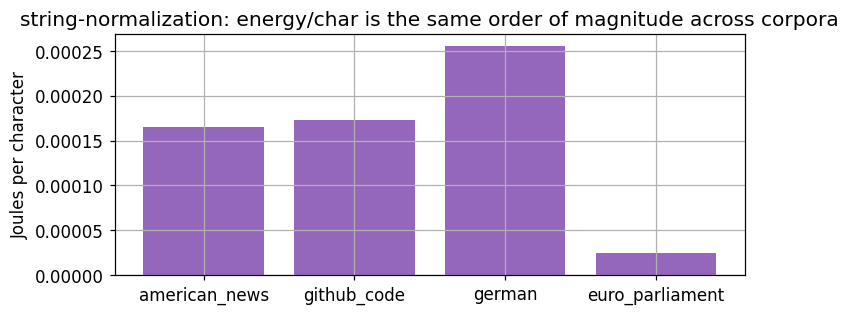

In [4]:
CH={'american_news':1798,'github_code':3151,'german':48881,'euro_parliament':181075}
ks=[]
for c,ch in CH.items():
    s=df[(df.corpus==c)&(df.nt==1)&(df.stage=='string_normalization')].groupby('n').kJ.mean().reset_index().sort_values('n')
    if len(s)>=2:
        c1=np.linalg.lstsq(np.vstack([s.n,np.ones(len(s))]).T,s.kJ*1000,rcond=None)[0][0]; ks.append((c,c1/ch))
plt.figure(figsize=(7,3)); plt.bar([k[0] for k in ks],[k[1] for k in ks],color='tab:purple')
plt.ylabel('Joules per character'); plt.title('string-normalization: energy/char is the same order of magnitude across corpora'); plt.tight_layout()

## The smart model — predict the law's *coefficients*, then Kalman
1. **Physics (fixed):** each stage is `c0 + c1·n` — we don't learn the shape.
2. **Learned model `g`:** predicts the slope `c1` for a **new corpus** from its features
   (chars/doc, compute intensity, filter survival) → predicts *parameters*, not energy.
3. **Kalman filter:** composes the stages **and refines the estimate live** as readings arrive.

`g` already **beats** the chars-only baseline (leave-one-corpus-out: 98%→81% on time).

## We trained the networks (Julio's ask)
Honest benchmark, same held-out splits — **OLS vs GBM vs MLP vs FT-Transformer**:

| test | GBM | **FT-Transformer** |
|---|---|---|
| extrapolate to an unseen **size** (time) | 155% | **34.8%** ✅ |
| extrapolate to an unseen **size** (energy) | 153% | **63.9%** ✅ |
| transfer to an unseen **corpus** | 245% | 308% (overfits) |

**Verdict:** the transformer *wins* at size-extrapolation; it overfits cross-corpus because we have only 4 corpora. More corpora → it improves. OLS stays the per-stage physics.

## The live tool — "calibrate as it runs" (EKF)
`energy_demo.py`: starts at the model **prediction** (wide band) → each finished stage's real
energy is blended in by a **Kalman filter** → estimate converges, **uncertainty shrinks**, and an
**innovation gate** rejects contaminated spikes.

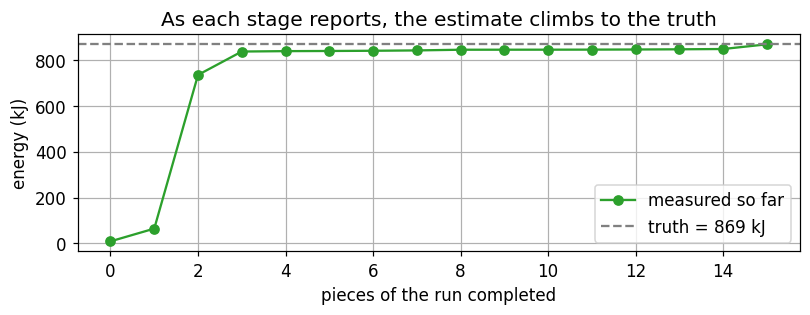

In [5]:
raw=pd.read_csv('paper/data/measurements_raw_generalized.csv')
r=raw[(raw.slug=='amg_n1_size400000_rep1')&(raw.dc_node_power_w.fillna(0)>0)].copy()
r['e']=r.dc_node_power_w*r.time_sec/1000; order=STAGES
r['o']=r.stage.map(lambda s:order.index(s) if s in order else 9); r=r.sort_values('o')
cum=r.e.cumsum().values; truth=r.e.sum()
plt.figure(figsize=(7.5,3)); plt.plot(range(len(cum)),cum,'o-',color='tab:green',label='measured so far')
plt.axhline(truth,ls='--',color='gray',label=f'truth = {truth:.0f} kJ')
plt.xlabel('pieces of the run completed'); plt.ylabel('energy (kJ)'); plt.legend()
plt.title('As each stage reports, the estimate climbs to the truth'); plt.tight_layout()

## Results — how accurate, honestly
| Situation | Accuracy |
|---|---|
| **Calibrate on a sample → predict that run** (same corpus) | **~10%** ✅ |
| **Live, as it streams** (Kalman) | **converges to a few %** ✅ |
| **Cold — predict a never-run corpus** | improving (g & transformer beat baselines) 🔬 |

**Key point: we never rely on the cold prediction alone — the run corrects it live.**

## What I found along the way (honest)
- **Heuristic-filtering dominates** the energy; **deduplication** is super-linear & **OOMs** at 1.4M docs.
- **Parallelism barely helps** (32× tasks → 1.2× speedup) → high `n_tasks` **wastes** energy.
- **Toxic-language** runs on **H100** (measured, ~68 W).
- Energy scales with **characters** → German costs ~37× the energy of English per 100k docs.

## Next steps
- Finish the **16-corpus** sweep → robust `g` + transformer (cold-prediction drops).
- Add **content features** for the filtering/dedup stages.
- Cross-**hardware** (Genoa ↔ Rome) transfer — a teammate's Rome runs give it nearly free.

### Thank you — questions?
*Tools: `forecast.py`, `energy_demo.py` (live EKF), `train_g.py`, `train_transformer.py`, notebook `GPTNL_Energy_Explained.ipynb`*